In [55]:
%load_ext autoreload
%autoreload 2
import numpy as np
import matplotlib.pyplot as plt
from coffea import util
from coffea.processor import accumulate
import os
import re
import pandas as pd
import hist
import matplotlib as mpl
import mplhep
import sys
import hist
import hist.intervals


sys.path.append("/uscms/home/reshmar/nobackup/IDMe_Run3_Collab/CMSSW_13_0_13/src/iDMe/python_analysis/analysisTools")
import plotTools as ptools
import utils

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [56]:
f_sig = "/uscms/home/reshmar/nobackup/IDMe_Run3_Collab/CMSSW_13_0_13/src/iDMe/python_analysis/coffea/AllInOne_2022/Res_LL_lxy.coffea"

sig_histo = util.load(f_sig) [0]

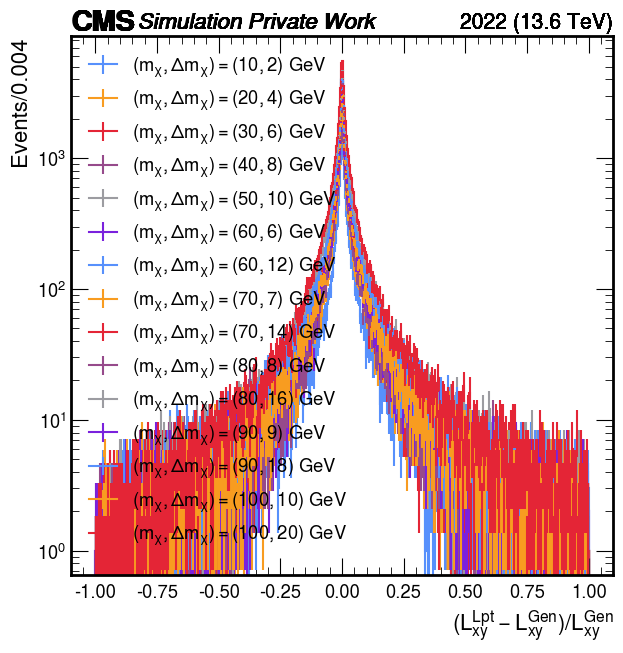

In [57]:
fig, ax = plt.subplots(figsize=(7,7))

# Plot settings
plot_dict = {
    'variable':'res_LPT_gen',
    'cut': 'cut1',
    'year': 2022
}

style_dict = {
    'fig': fig,
    'ax': ax,
    'rebin': None,
    'xlim': None,     # if None, the default will show up; otherwise give as a list, i.e. [0, 10]
    'doLogy': True,
    'doLogx': False,
    'doDensity': False,
    'doYerr': True,
    'xlabel': r"$(L_{xy}^{\mathrm{Lpt}}-L_{xy}^{\mathrm{Gen}})/L_{xy}^{\mathrm{Gen}}$",
    'ylabel': None,   # if None, the default will show up; otherwise give as a string, i.e. 'Efficiency'
    'label': None,    # if None, the default will show up; otherwise give as a string, i.e. 'Highest ctau signal samples'
    'flow': None,     # overflow
    'doSave': False,
    'outDir': './plots/signal_2018',
    'outName': f'gen_ele_vxy10_m110.png'
}

#signal points
samples = {
    10:
    {

        0.2: [100],

    },

    20:
    {

        0.2: [100],

    },
    30:
    {

        0.2: [100]
    },
    40:
    {
        0.2: [100],
    },
    50:
    {

        0.2: [100],
    },
    60:
    {

         0.1: [100],
         0.2: [100]

    },
    70:
    {    0.1: [100],
         0.2: [100],
    },
    80:
    {    0.1: [100],
         0.2: [100],
    },
    90:
    {    0.1: [100],
         0.2: [100],
    },
    100:
    {    0.1: [100],
         0.2: [100],
    }

}



h_list_lpt=[]
h_sum_lpt = None

for m1,deltas in samples.items():
    for delta, ctaus in deltas.items():
        for ctau in ctaus:
            h_lpt = ptools.plot_signal_1D(sig_histo, m1, delta, ctau, plot_dict, style_dict)
            h_list_lpt.append(h_lpt)            
            if h_sum_lpt is None:
                h_sum_lpt = h_lpt.copy()
            else:
                h_sum_lpt += h_lpt


In [58]:
# Desired residual-bin width. Set to None to keep the original binning.
res_bin_width = 0.008

# Residual range used by curve_fit (this affects the fitted result).
fit_min = -0.3
fit_max =  0.3

# Residual x-axis range shown on the fit plot (display only).
plot_min = -0.5
plot_max =  0.5

# Draw the fitted DSCB curve on top of the data points?
show_fit_curve = True

# ----- Build the histogram that will be used below -----
h_fit_lpt = h_sum_lpt

original_edges = h_sum_lpt.axes[0].edges
# print ("original_edges=", original_edges)
original_widths = np.diff(original_edges)

if res_bin_width is not None:
    # Automatic rebinning below assumes the stored residual axis has uniform bins.
    if not np.allclose(original_widths, original_widths[0]):
        raise ValueError(
            "The stored residual axis has variable-width bins. "
            "Use an explicit grouping/rebinning scheme instead of res_bin_width."
        )

    original_bin_width = original_widths[0]
    rebin_factor = int(round(res_bin_width / original_bin_width))

    if rebin_factor < 1:
        raise ValueError(
            f"Requested bin width {res_bin_width:g} is finer than the stored "
            f"bin width {original_bin_width:g}. The .coffea histogram must be "
            "created with finer bins upstream if you want that."
        )

    actual_bin_width = rebin_factor * original_bin_width
    if not np.isclose(actual_bin_width, res_bin_width):
        raise ValueError(
            f"Requested bin width {res_bin_width:g} is not an integer multiple "
            f"of the stored width {original_bin_width:g}. Try one of "
            f"{original_bin_width:g}, {2*original_bin_width:g}, "
            f"{3*original_bin_width:g}, ..."
        )

    h_fit_lpt = h_sum_lpt[hist.rebin(rebin_factor)]      # 1D: no leading ':' (the 2D one was [:, hist.rebin(n)])
    print(f"Original residual bin width : {original_bin_width:g}")
    print(f"Rebin factor                : {rebin_factor}")
    print(f"Residual bin width used     : {actual_bin_width:g}")
else:
    print("Using the original residual binning.")

print(f"Fit range                   : [{fit_min}, {fit_max}]")
print(f"Displayed x range           : [{plot_min}, {plot_max}]")

Original residual bin width : 0.004
Rebin factor                : 2
Residual bin width used     : 0.008
Fit range                   : [-0.3, 0.3]
Displayed x range           : [-0.5, 0.5]


In [59]:

first_data = []

bin_edges = h_fit_lpt.axes[0].edges
bincenters = (bin_edges[1:]+bin_edges[:-1])/2

counts = h_fit_lpt.values()
variances = h_fit_lpt.variances()
yerr = np.sqrt(variances)

first_data.append({"label": "All signal points summed", "xdata": bincenters, "ydata": counts, "yerror": yerr} )



In [60]:
for data in first_data:
    x = data["xdata"]
    y = data["ydata"]
    sig = data["yerror"]

    # Keep only populated bins inside the chosen fit range.
    # Changing fit_min / fit_max changes which points are given to curve_fit.
    mask = (y > 0) & (x >= fit_min) & (x <= fit_max)

    data["y_new_data"] = y[mask]
    data["x_new_data"] = x[mask]
    data["yerr_new_data"] = sig[mask]

In [61]:
first_data = [data for data in first_data
              if (len(data["y_new_data"]) )> 0]

In [62]:
n_parameters = 7
first_data = [data for data in first_data
              if (len(data["y_new_data"]) )> n_parameters]

if len(first_data) == 0:
    raise ValueError("Not enough populated bins in [fit_min, fit_max] to fit the 7 DSCB parameters.")
print(f"Points used in the fit: {len(first_data[0]['y_new_data'])}")

Points used in the fit: 74


In [63]:
#1. Define your model

def double_cb(x,u,sig, nl, a_l, nr, a_r,N):

    t=(x-u)/(sig)
    al = abs(a_l)
    ar = abs(a_r)

    left_tail = t < -al
    core = (t>= -al) & (t<=ar)
    right_tail = t > ar

    y=np.empty_like(t)

    y[core] = np.exp(-0.5*t[core]*t[core])

    A_L = (nl / al)**nl * np.exp(-0.5 * al**2)
    B_L = (nl / al) - al
    y[left_tail] = A_L / (B_L - t[left_tail])**nl

    A_R = (nr / ar)**nr * np.exp(-0.5 * ar**2)
    B_R = (nr / ar) - ar
    y[right_tail] = A_R / (B_R + t[right_tail])**nr

    return N*y

All signal points summed
  mean  = 0.00005 ± 0.00002
  sigma = 0.00588 ± 0.00003
  chi2/ndof = 675.3/67 = 10.08


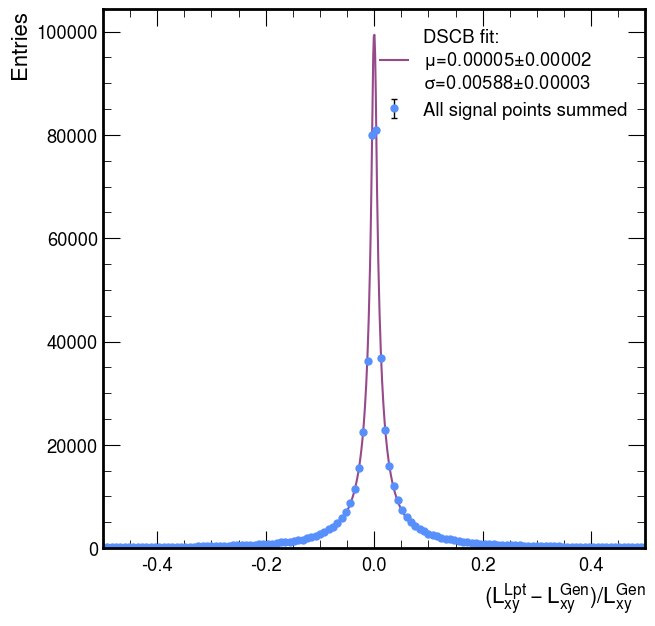

In [64]:
from scipy.optimize import curve_fit

fit_data=[]

for data in first_data:
    plt.figure(figsize=(7, 7))

    mplhep.histplot(h_fit_lpt, histtype='errorbar', yerr=True, capsize=2, ecolor='black', label=data["label"])

    mean0 = np.average(data["x_new_data"], weights=data["y_new_data"])
    sigma0 = np.sqrt(np.average((data["x_new_data"]-mean0)**2, weights=data["y_new_data"]))

   # [mean, sigma, nl, al, nr, ar, N]
    initial_guess = [mean0, sigma0, 1, 0.2, 1, 0.2, data["y_new_data"].max()]

    lower = [data["x_new_data"].min(), 1e-5, 0.5, 0.05, 0.1, 0.05, 0]
    upper = [data["x_new_data"].max(), (data["x_new_data"].max()-data["x_new_data"].min()), 2, 1, 5, 2, 5*data["y_new_data"].max()]

    popt, pcov = curve_fit(double_cb, data["x_new_data"], data["y_new_data"], p0=initial_guess, sigma=data["yerr_new_data"], absolute_sigma=True, bounds=(lower, upper), maxfev=20000)
    perr = np.sqrt(np.diag(pcov))

    yp = double_cb(data["x_new_data"], *popt)

    eq = (data["y_new_data"]-yp)/(data["yerr_new_data"])
    chi2 = np.sum(eq**2)

    ndof = len(data["y_new_data"]) - len(popt)

    chi2ndof = chi2/ndof

    fit_mean = f"{popt[0]:.5f} ± {perr[0]:.5f}"
    fit_sigma = f"{popt[1]:.5f} ± {perr[1]:.5f}"
    print(data["label"])
    print("  mean  =", fit_mean)
    print("  sigma =", fit_sigma)
    print(f"  chi2/ndof = {chi2:.1f}/{ndof} = {chi2ndof:.2f}")

    fit_data.append({"label":data["label"], "fit_mean": popt[0], "fit_mean_unc": perr[0], "fit_sigma":popt[1],"fit_sigma_unc":perr[1], "chi2/ndof":chi2ndof, "ndof":ndof})

    # Smooth curve for display across the selected fit range.
    x_fit_plot = np.linspace(data["x_new_data"].min(), data["x_new_data"].max(), 500)
    if show_fit_curve:
        plt.plot(x_fit_plot, double_cb(x_fit_plot, *popt), color='C3', label=(rf"DSCB fit:" "\n"    rf"$\mu$={popt[0]:.5f}$\pm${perr[0]:.5f}" "\n"
                    rf"$\sigma$={popt[1]:.5f}$\pm${perr[1]:.5f}"))
    plt.xlabel(r'$(L_{xy}^{\mathrm{Lpt}}-L_{xy}^{\mathrm{Gen}})/L_{xy}^{\mathrm{Gen}}$')
    plt.ylabel("Entries")
    plt.xlim(plot_min, plot_max)
    plt.legend(loc='upper right')
    plt.show()

In [65]:
# Replaces the "sigma vs Gen bin" plot of the 2D notebook: with a single 1D histogram there is only
# one fitted sigma, so we just tabulate the result.
results_df = pd.DataFrame(fit_data)
results_df

,label,fit_mean,fit_mean_unc,fit_sigma,fit_sigma_unc,chi2/ndof,ndof
0,All signal points summed,0.000049,0.000022,0.005884,0.000033,10.079474,67
